In [ ]:
from google.colab.drive import mount
import numpy as np
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df=pd.read_csv("/content/drive/MyDrive/mizo_praat/Mizo_data_2.csv")
df
# df = df.replace([' HS'],'HS')
# df=df.replace(['LLU'],'LU')
# df=df.replace([' LS'],'LS')
# #df=df.replace(['nan'],'LS')

df=df.replace(['H U'],'HU')
df=df.replace(['LLU'],'LU')
df=df.replace([' LS'],'LS')
df=df.replace([' HS'],'HS')

df['Tone_Stress'].unique()

array(['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'], dtype=object)

In [ ]:
df.columns


Index(['F1', 'F2', 'F3', 'F4', 'F5', 'intensityMin', 'intensityMax',
       'intensityAvg', 'intensityStdev', 'intensityRange', 'duration',
       'maxF0_Hz', 'minF0_Hz', 'meanF0_Hz', 'f0Range_Hz', 'Tone_Stress'],
      dtype='object')

In [ ]:
df ['Tone_Stress'] = df ['Tone_Stress'].fillna (0)
df ['duration'] = df ['duration'].fillna (0)
df ['maxF0_Hz'] = df ['maxF0_Hz'].fillna (0)
df ['minF0_Hz'] = df ['minF0_Hz'].fillna (0)
df ['meanF0_Hz'] = df ['meanF0_Hz'].fillna (0)
df ['f0Range_Hz'] = df ['f0Range_Hz'].fillna (0)
df ['intensityMin'] = df ['intensityMin'].fillna (0)
df ['intensityMax'] = df ['intensityMax'].fillna (0)
df ['intensityAvg'] = df ['intensityAvg'].fillna (0)
df ['intensityStdev'] = df ['intensityStdev'].fillna (0)
df ['intensityRange'] = df ['intensityRange'].fillna (0)
df ['F1'] = df ['F1'].fillna (0)
df ['F2'] = df ['F2'].fillna (0)
df ['F3'] = df ['F3'].fillna (0)
df ['F4'] = df ['F4'].fillna (0)
df ['F5'] = df ['F5'].fillna (0)

In [ ]:
from sklearn.model_selection import train_test_split
X = df.iloc[:,:-1]
y =  df.iloc[: ,-1:]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
np.any(np.isnan(X_train))
X_train = X_train.fillna(X_train.mean())
np.any(np.isnan(X_train))
df

,F1,F2,F3,F4,F5,intensityMin,intensityMax,intensityAvg,intensityStdev,intensityRange,duration,maxF0_Hz,minF0_Hz,meanF0_Hz,f0Range_Hz,Tone_Stress
0,503.72,1143.47,2486.32,3574.73,4942.23,68.18,83.88,79.04,5.60,15.70,0.08,97.05,95.88,96.56,1.17,LU
1,924.76,1488.15,3108.87,4056.19,5074.83,59.83,75.49,67.66,5.89,15.66,0.13,86.25,67.89,80.40,18.36,LS
2,347.63,966.57,2918.01,3298.62,4780.20,68.41,83.21,80.87,3.85,14.80,0.20,123.49,116.71,121.51,6.78,LU
3,361.17,1403.90,2423.70,3512.36,4768.58,64.71,83.81,76.80,5.79,19.11,0.22,87.79,73.55,79.89,14.23,FS
4,274.39,2218.55,2540.21,3414.52,4761.45,62.41,84.24,78.00,7.03,21.84,0.22,127.86,50.99,118.93,76.87,HU
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,467.58,2486.51,2969.06,4185.61,4250.46,66.46,79.36,73.49,4.07,12.90,0.20,232.49,206.32,220.45,26.16,FS
1482,349.28,2464.30,3085.60,4351.04,4681.18,45.38,74.79,65.97,8.90,29.41,0.25,201.61,162.32,175.74,39.29,RU
1483,389.16,1364.53,2303.59,3650.20,4741.31,49.18,77.57,72.29,7.02,28.39,0.19,255.90,197.79,217.54,58.11,FS
1484,403.60,2262.96,3053.24,3957.56,4318.53,43.29,76.30,69.93,8.67,33.01,0.21,275.01,157.01,206.82,118.00,FS


In [ ]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
df.isnull().any().any()

False

USING DECISION TREE

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
dt = DecisionTreeClassifier( max_depth=3, random_state=7)
dt.fit(X_train,y_train)
y_pred2= dt.predict(X_test)
acc1 = accuracy_score(y_test,y_pred2)*100
p=precision_score(y_test,y_pred2, average='micro')
recall = recall_score(y_test,y_pred2,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc1)
F1_score=f1_score(y_test,y_pred2,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.3288590604026846
Recall:  0.3288590604026846
Accuracy:  32.88590604026846
F1 Score:  0.3288590604026846


CONFUSION MATRIX FOR DECISION TREE

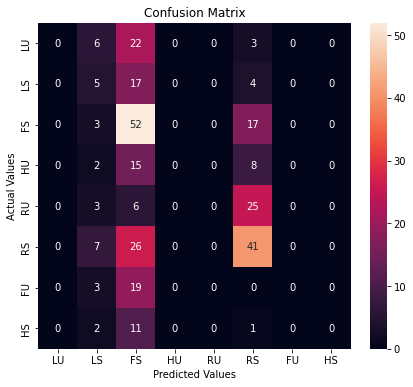

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred2)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

DECISION TREE K-CROSS VALIDATION

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
#dt = DecisionTreeClassifier( max_depth=3, random_state=7)

rf =DecisionTreeClassifier( max_depth=3, random_state=7)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


Cross-validation scores:[0.31092437 0.33613445 0.26890756 0.32911392 0.32067511]


USING GAUSSIAN NAIVE BAYES

In [ ]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()

model.fit(X_train,y_train)
pred = model.predict(X_test)
# print(pred)
from sklearn.metrics import accuracy_score
acc2 = accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc2)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.2516778523489933
Recall:  0.2516778523489933
Accuracy:  25.16778523489933
F1 Score:  0.2516778523489933


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
df
first_column = df.columns[0]
# Delete first
df = df.drop([first_column], axis=1)
df

,F2,F3,F4,F5,intensityMin,intensityMax,intensityAvg,intensityStdev,intensityRange,duration,maxF0_Hz,minF0_Hz,meanF0_Hz,f0Range_Hz,Tone_Stress
0,1143.47,2486.32,3574.73,4942.23,68.18,83.88,79.04,5.60,15.70,0.08,97.05,95.88,96.56,1.17,LU
1,1488.15,3108.87,4056.19,5074.83,59.83,75.49,67.66,5.89,15.66,0.13,86.25,67.89,80.40,18.36,LS
2,966.57,2918.01,3298.62,4780.20,68.41,83.21,80.87,3.85,14.80,0.20,123.49,116.71,121.51,6.78,LU
3,1403.90,2423.70,3512.36,4768.58,64.71,83.81,76.80,5.79,19.11,0.22,87.79,73.55,79.89,14.23,FS
4,2218.55,2540.21,3414.52,4761.45,62.41,84.24,78.00,7.03,21.84,0.22,127.86,50.99,118.93,76.87,HU
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,2486.51,2969.06,4185.61,4250.46,66.46,79.36,73.49,4.07,12.90,0.20,232.49,206.32,220.45,26.16,FS
1482,2464.30,3085.60,4351.04,4681.18,45.38,74.79,65.97,8.90,29.41,0.25,201.61,162.32,175.74,39.29,RU
1483,1364.53,2303.59,3650.20,4741.31,49.18,77.57,72.29,7.02,28.39,0.19,255.90,197.79,217.54,58.11,FS
1484,2262.96,3053.24,3957.56,4318.53,43.29,76.30,69.93,8.67,33.01,0.21,275.01,157.01,206.82,118.00,FS


CONFUSION MATRIX FOR NAIVE BAYES

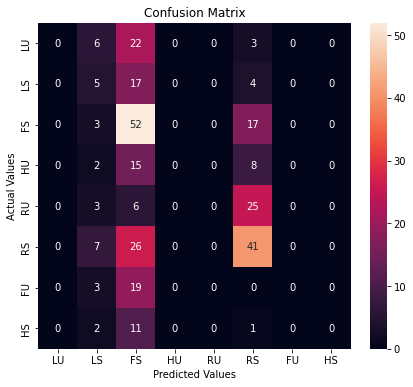

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
#cm_df = pd.DataFrame(cm,index = ['LS', 'LU', 'HS', 'HU'],columns = ['LS', 'LU', 'HS', 'HU'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

rf =GaussianNB()
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


Cross-validation scores:[0.25630252 0.24369748 0.26890756 0.24472574 0.24050633]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example usin

USING LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver = 'newton-cg',multi_class='auto',max_iter=1000)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
from sklearn.metrics import accuracy_score
acc3 = accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc3)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Precision:  0.40604026845637586
Recall:  0.40604026845637586
Accuracy:  40.604026845637584
F1 Score:  0.40604026845637586


/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,


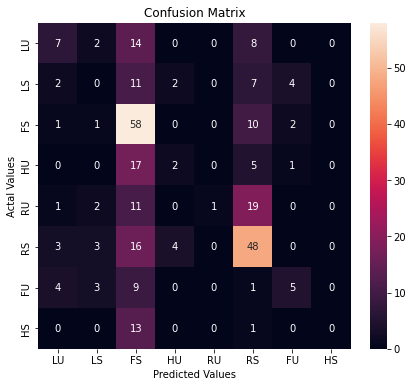

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression


rf =LogisticRegression(solver = 'newton-cg',multi_class='auto',max_iter=1000)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed 

Cross-validation scores:[0.36554622 0.35294118 0.31512605 0.35021097 0.33333333]


/usr/local/lib/python3.7/dist-packages/sklearn/utils/optimize.py:212: ConvergenceWarning: newton-cg failed to converge. Increase the number of iterations.
  ConvergenceWarning,


LOGISTIC REGRESSION WITH PIPE LINE

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=100000,solver='lbfgs'))
pipe.fit(X_train, y_train)  # apply scaling on train
pred=pipe.predict(X_test)
# print(pred)
pipe.score(X_test, y_test)
acc4=accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc4)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.3790322580645161
Recall:  0.3790322580645161
Accuracy:  37.903225806451616
F1 Score:  0.3790322580645161


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


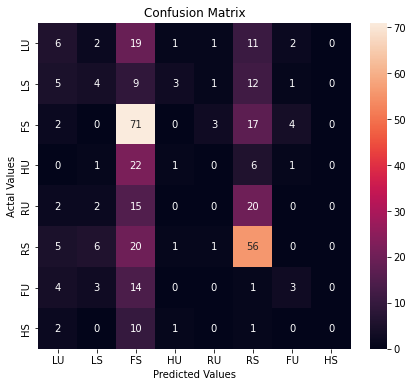

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


rf =make_pipeline(StandardScaler(), LogisticRegression(max_iter=100000,solver='lbfgs'))
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))


/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example usin

Cross-validation scores:[0.35874439 0.37219731 0.34977578 0.37668161 0.36486486]


KNN

In [ ]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, MaxAbsScaler

x_data = df.drop(['Tone_Stress'],axis=1)
y_data = df['Tone_Stress']
#MinMaxScaler = preprocessing.MinMaxScaler()
RobustScaler = preprocessing.RobustScaler()
#X_data_minmax = MinMaxScaler.fit_transform(x_data)
X_data_minmax = RobustScaler.fit_transform(x_data)
data = pd.DataFrame(X_data_minmax)

data.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,-0.475392,-0.665341,-0.303411,0.925587,0.008322,0.275960,0.155747,0.374121,0.076858,-1.714286,-0.696835,0.012109,-0.381596,-0.765457
1,0.013095,0.591873,0.419133,1.699486,-0.653457,-2.110953,-2.288937,0.455696,0.073461,-1.000000,-0.955766,-0.732801,-0.789573,-0.195591
2,-0.726098,0.206439,-0.717779,-0.020077,0.026550,0.085349,0.548872,-0.118143,0.000425,0.000000,-0.062935,0.566467,0.248296,-0.579480
3,-0.106306,-0.791799,-0.397012,-0.087895,-0.266693,0.256046,-0.325456,0.427567,0.366454,0.285714,-0.918844,-0.582169,-0.802449,-0.332505
4,1.048231,-0.556512,-0.543844,-0.129509,-0.448980,0.378378,-0.067669,0.776371,0.598301,0.285714,0.041836,-1.182568,0.183161,1.744074


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
X_train, X_test, y_train, y_test = train_test_split(data, y_data,test_size=0.2, random_state = 1)
knn_clf=KNeighborsClassifier()
knn_clf.fit(X_train,y_train)
ypred=knn_clf.predict(X_test)

result = confusion_matrix(y_test, ypred)
print("Confusion Matrix:")
print(result)
result1 = classification_report(y_test, ypred)
print("Classification Report:")
print (result1)
result2= accuracy_score(y_test,ypred)
acc5=result2*100
print("Accuracy:",acc5)
p=precision_score(y_test,ypred, average='micro')
recall = recall_score(y_test,ypred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc5)
F1_score=f1_score(y_test,ypred,average='micro')
print('F1 Score: ',F1_score)

Confusion Matrix:
[[15  2  8  2  2  4  5  2]
 [ 9  5  2  2  2  8  1  0]
 [ 8  2 42  8  6  5  2  1]
 [ 2  1  9  3  2  2  1  0]
 [ 3  1  7  1  4  7  2  0]
 [ 6  9 14  4 13 27  0  0]
 [ 7  2  6  3  1  0  3  1]
 [ 3  1  6  0  0  0  4  0]]
Classification Report:
              precision    recall  f1-score   support

          FS       0.28      0.38      0.32        40
          FU       0.22      0.17      0.19        29
          HS       0.45      0.57      0.50        74
          HU       0.13      0.15      0.14        20
          LS       0.13      0.16      0.15        25
          LU       0.51      0.37      0.43        73
          RS       0.17      0.13      0.15        23
          RU       0.00      0.00      0.00        14

    accuracy                           0.33       298
   macro avg       0.24      0.24      0.23       298
weighted avg       0.33      0.33      0.32       298

Accuracy: 33.22147651006711
Precision:  0.33221476510067116
Recall:  0.33221476510067116
Ac

CONFUSION MATRIX FOR KNN

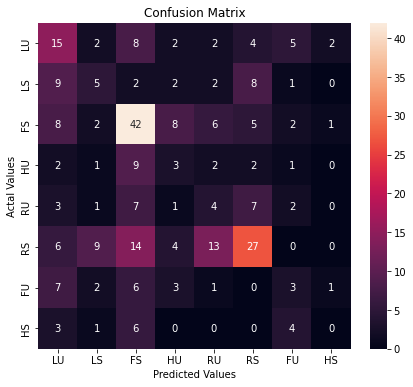

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, ypred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
#from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

rf =KNeighborsClassifier()
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.3487395  0.35294118 0.28991597 0.24050633 0.24894515]


SUPPORT VECTOR MACHINE

In [ ]:
from sklearn.svm import SVC
svc1 = SVC(C=1,kernel='rbf',gamma=1,max_iter=10000,random_state=101)     
svc1.fit(X_train,y_train)
y_pred = svc1.predict(X_test)
from sklearn.metrics import accuracy_score
acc6= accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc6)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.3825503355704698
Recall:  0.3825503355704698
Accuracy:  38.25503355704698
F1 Score:  0.3825503355704698


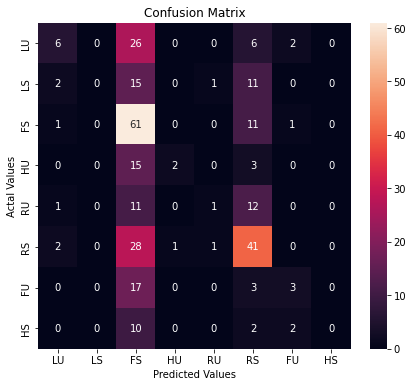

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:

from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

rf =SVC(C=1,kernel='rbf',gamma=1,max_iter=10000,random_state=101)
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.34453782 0.33613445 0.33613445 0.32911392 0.33755274]


ENSEMBLE LEARNING

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
bagging = BaggingClassifier(RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15),max_samples=0.5, max_features=0.5)
bagging.fit(X_train, y_train)
pred=bagging.predict(X_test)
acc7=accuracy_score(y_test,pred)*100
p=precision_score(y_test,pred, average='micro')
recall = recall_score(y_test,pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc7)
F1_score=f1_score(y_test,pred,average='micro')
print('F1 Score: ',F1_score)

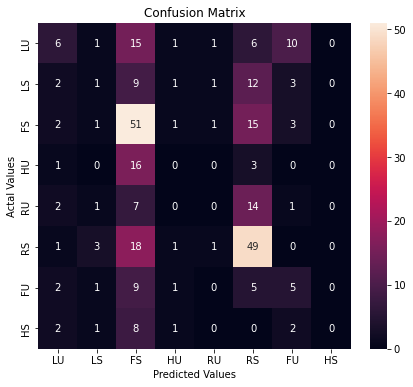

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = BaggingClassifier(RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15),max_samples=0.5, max_features=0.5)   
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    

scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.34033613 0.3697479  0.36134454 0.32489451 0.34599156]


RANDOM FOREST

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
# from sklearn.externals import joblib
from sklearn.metrics import accuracy_score

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
classifier = RandomForestClassifier(n_estimators = 200, criterion = 'entropy', random_state =42,max_depth=15)
classifier.fit(X_train, y_train)
# Predicting the Test set results
y_pred = classifier.predict(X_test)
acc8=accuracy_score(y_test,y_pred)*100
p=precision_score(y_test,y_pred, average='micro')
recall = recall_score(y_test,y_pred,average='micro')
print('Precision: ',p)
print('Recall: ',recall)
print('Accuracy: ',acc8)
F1_score=f1_score(y_test,y_pred,average='micro')
print('F1 Score: ',F1_score)

Precision:  0.37583892617449666
Recall:  0.37583892617449666
Accuracy:  37.58389261744966
F1 Score:  0.3758389261744966


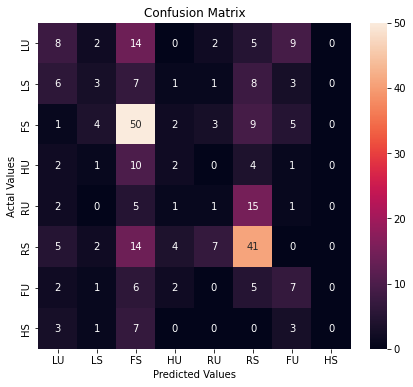

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
# Creating  a confusion matrix,which compares the y_test and y_pred
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,index = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'],columns = ['LU', 'LS', 'FS', 'HU', 'RU', 'RS', 'FU', 'HS'])
plt.figure(figsize=(7,6))
sns.heatmap(cm_df, annot=True,annot_kws={"size": 10},fmt="d")
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
#from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100,random_state=1, n_jobs=-1)    
rf.fit(X_train, y_train)    
y_train_pred = rf.predict(X_train)    
y_test_pred = rf.predict(X_test)    
#y_all_pred = rf.predict(xsetr)    
from sklearn.model_selection import cross_val_score
scores = cross_val_score(rf,X=X_train, y=y_train, cv=5)    
print("Cross-validation scores:{}".format(scores))

Cross-validation scores:[0.36554622 0.39495798 0.41176471 0.35021097 0.37552743]


Chart

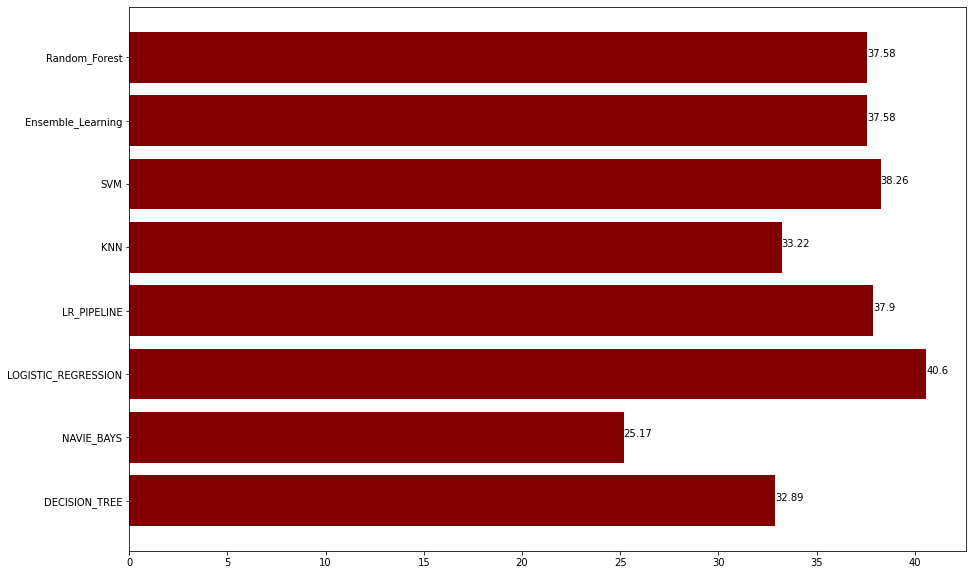

In [ ]:

import matplotlib.pyplot as plt
Model = ["DECISION_TREE",  "NAVIE_BAYS", "LOGISTIC_REGRESSION","LR_PIPELINE","KNN","SVM","Ensemble_Learning","Random_Forest"]
#acc = [round(acc1,2),round(acc2,2), round(acc3,2),round(acc4,2),round(acc5,2),round(acc6,2),round(acc7,2),round(acc8,2)]
acc = [round(acc1,2),round(acc2,2), round(acc3,2),round(acc4,2),round(acc5,2),round(acc6,2),round(acc7,2),round(acc8,2)]
fig = plt.figure(figsize = (15,10 ))
plt.barh(Model,acc,color="maroon")
for index, value in enumerate(acc):
  plt.text(value, index,str(value))
plt.show()  